# Лабораторная работа №1. Описательная статистика и первые гипотезы

## Контекст задачи

Вы — аналитик данных в страховой компании **MedGuard**, которая продаёт полисы добровольного медицинского страхования (ДМС) в четырёх регионах США.

Продакт-менеджер (PM) готовит пересмотр тарифов и маркетинговой стратегии на следующий год. Перед тем как обсуждать что-либо с финансовым отделом, ему нужен **фактический портрет клиентской базы** и проверка нескольких утверждений, которые сейчас в компании принимаются «на веру».

Из внутренней переписки PM:

> «У нас есть выгрузка по 1 338 застрахованным за прошлый год. Мне нужно понять, кто наши клиенты, сколько мы на них реально тратим, и правда ли то, что говорят маркетинг и финансы. Ответы нужны с цифрами, а не с ощущениями. Каждый вывод — с обоснованием, почему ты в нём уверен».

**Ваша задача** — пройти по данным от описательной статистики до проверки гипотез и в конце написать короткий отчёт для PM.

---

## Датасет

Используем открытый датасет **Medical Cost Personal Dataset** (страховые выплаты по клиентам).

**Скачайте файл самостоятельно** по ссылке и положите его в одну папку с этим ноутбуком:

- https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv (правая кнопка → «Сохранить как…» → `insurance.csv`)
- Зеркало на Kaggle: https://www.kaggle.com/datasets/mirichoi0218/insurance

Описание колонок:

| Колонка | Описание |
|---|---|
| `age` | возраст застрахованного, лет |
| `sex` | пол: `male` / `female` |
| `bmi` | индекс массы тела (кг/м²) |
| `children` | количество детей, покрытых полисом |
| `smoker` | курит ли клиент: `yes` / `no` |
| `region` | регион проживания: `northeast`, `northwest`, `southeast`, `southwest` |
| `charges` | сумма страховых выплат за год, USD |

---

## Правила выполнения

1. Все расчёты — в коде (`numpy`, `pandas`, `scipy.stats`, `matplotlib`/`seaborn`), как в лекции.
2. После каждого задания — **вывод СВОИМИ словами** в markdown-ячейке: что посчитали, что это значит для бизнеса.
3. Уровень значимости во всех проверках гипотез: $\alpha = 0.05$.
4. Для проверки гипотез используем **z-критерий для среднего** и доверительные интервалы, как в лекции (выборка большая, $N > 30$, поэтому вместо $\sigma$ ГС берём $sd$ выборки).
5. Ячейки с `# ваш код` — заполняете вы. Ячейки с `**Вывод:**` — тоже вы.

In [1]:
import math
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
np.random.seed(42)  # чтобы результаты со случайностью воспроизводились

df = pd.read_csv("insurance.csv")
print(df.shape)
df.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Задание 1. Знакомство с данными и типы переменных

PM просит для начала «просто описать, что у нас за таблица». Но прежде чем считать хоть что-то, нужно понять, **с какими типами переменных** мы работаем — от этого зависит, какие меры и графики допустимы.

**1.1.** Выведите общую информацию о таблице: количество строк и столбцов, типы данных, наличие пропусков (`df.info()`, `df.isna().sum()`, `df.describe(include="all")`).

**1.2.** Заполните таблицу ниже: для каждой колонки определите тип переменной по классификации из лекции
(количественная непрерывная / количественная дискретная / номинативная / ранговая) и **обоснуйте в одном предложении**.

**1.3.** Ответьте: для какой из колонок будет **ошибкой** считать среднее значение, даже если pandas это позволит? Почему?

In [2]:
df.info()
print("\nПропуски по колонкам:")
print(df.isna().sum())
print("\nПолных дубликатов строк:", df.duplicated().sum())
df.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

Пропуски по колонкам:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Полных дубликатов строк: 1


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


**Вывод (заполните таблицу):**

| Колонка | Тип переменной | Обоснование |
|---|---|---|
| `age` | количественная (дискретная по записи, по сути непрерывная) | Возраст измеряется в годах — это число, с которым имеют смысл арифметические операции; в данных он округлён до целых лет, поэтому формально значения дискретны. |
| `sex` | номинативная (бинарная) | Две категории `male`/`female` без естественного порядка — их можно только сравнивать на «равно/не равно». |
| `bmi` | количественная непрерывная | Отношение массы к квадрату роста, может принимать любое дробное значение в диапазоне (в данных 15.96–53.13). |
| `children` | количественная дискретная | Количество детей — целое число 0–5, разность и среднее имеют смысл («в среднем 1.09 ребёнка»), но промежуточных значений не бывает. |
| `smoker` | номинативная (бинарная) | Две категории `yes`/`no`, порядка нет; доля курильщиков считается, но «среднее курение» — нет. |
| `region` | номинативная | Четыре названия регионов, никакого порядка или расстояния между ними нет. |
| `charges` | количественная непрерывная | Денежная сумма в USD с копейками, любое неотрицательное значение. |

Ранговых (порядковых) переменных в таблице нет. Пропусков нет ни в одной колонке; есть 1 полностью дублирующаяся строка — для 1 338 записей это несущественно, и мы её оставляем (это могут быть два разных клиента с одинаковыми характеристиками).

**Ответ на 1.3:** ошибкой будет считать среднее для **`region`** (и вообще для номинативных `sex`, `smoker`, `region`). Если закодировать регионы числами 0–3, pandas спокойно посчитает, например, «1.52», но это число ничего не значит: коды присвоены произвольно, при другой кодировке «среднее» будет другим. Для номинативных переменных допустима только мода и доли категорий. (Для бинарных `sex`/`smoker`, закодированных 0/1, среднее совпадает с долей единиц — это единственный случай, когда такое «среднее» интерпретируемо, но правильно называть его именно долей.)

## Задание 2. Генеральная совокупность и выборка

Финансовый отдел предлагает сэкономить: вместо обработки всей базы делать выводы по **выборке из 100 клиентов**. PM спрашивает, насколько это безопасно и как правильно отобрать этих 100 человек.

В рамках задания считаем, что наша таблица из 1 338 клиентов — это **генеральная совокупность (ГС)**.

**2.1.** Сделайте **простую случайную выборку** из 100 клиентов (`df.sample(n=100, random_state=...)`). Сравните среднее `charges` и долю курильщиков в выборке и в ГС.

**2.2.** Сделайте **стратифицированную выборку** из 100 клиентов, где страты — это `region` (из каждого региона берём пропорционально его доле в ГС; подсказка: `df.groupby("region", group_keys=False).apply(lambda g: g.sample(frac=100/len(df), random_state=...))`). Сравните те же показатели с ГС.

**2.3.** Повторите простую случайную выборку 5 раз с разными `random_state` и посмотрите, как «прыгает» среднее `charges`. Запишите минимальное и максимальное полученное среднее.

**2.4.** Ответьте PM: можно ли принимать решения по одной выборке из 100 клиентов? Какой из двух способов отбора вы бы рекомендовали и почему? Какие ещё страты (кроме региона) имело бы смысл использовать в этой задаче?

In [3]:
RS = 42
gs_mean = df.charges.mean()
gs_smoker = (df.smoker == "yes").mean()

srs = df.sample(n=100, random_state=RS)
compare = pd.DataFrame({
    "ГС (1338)": [gs_mean, gs_smoker],
    "Простая случайная (100)": [srs.charges.mean(), (srs.smoker == "yes").mean()],
}, index=["Среднее charges, USD", "Доля курильщиков"])
compare.round(3)

,ГС (1338),Простая случайная (100)
"Среднее charges, USD",13270.422,13807.148
Доля курильщиков,0.205,0.220


In [4]:
# аналог подсказки groupby(...).apply(lambda g: g.sample(frac=...)); в новых версиях pandas
# apply убирает колонку группировки, поэтому выбираем все колонки явно
strat = df.groupby("region", group_keys=False)[df.columns.tolist()].apply(
    lambda g: g.sample(frac=100 / len(df), random_state=RS)
)
print("Размер стратифицированной выборки:", len(strat), "(округление долей регионов)")
print(pd.DataFrame({"ГС": df.region.value_counts(normalize=True),
                    "Страт. выборка": strat.region.value_counts(normalize=True)}).round(3))

compare["Стратифицированная по region"] = [strat.charges.mean(), (strat.smoker == "yes").mean()]
compare.round(3)

Размер стратифицированной выборки: 99 (округление долей регионов)
              ГС  Страт. выборка
region                          
northeast  0.242           0.242
northwest  0.243           0.242
southeast  0.272           0.273
southwest  0.243           0.242


,ГС (1338),Простая случайная (100),Стратифицированная по region
"Среднее charges, USD",13270.422,13807.148,12130.287
Доля курильщиков,0.205,0.220,0.202


In [5]:
means = {rs: df.sample(n=100, random_state=rs).charges.mean() for rs in [1, 2, 3, 4, 5]}
for rs, m in means.items():
    print(f"random_state={rs}: среднее charges = {m:,.0f} USD (отклонение от ГС {m - gs_mean:+,.0f})")
print(f"\nmin = {min(means.values()):,.0f} USD, max = {max(means.values()):,.0f} USD, "
      f"разброс = {max(means.values()) - min(means.values()):,.0f} USD; среднее ГС = {gs_mean:,.0f} USD")

random_state=1: среднее charges = 14,859 USD (отклонение от ГС +1,589)
random_state=2: среднее charges = 12,067 USD (отклонение от ГС -1,203)
random_state=3: среднее charges = 12,531 USD (отклонение от ГС -739)
random_state=4: среднее charges = 12,838 USD (отклонение от ГС -433)
random_state=5: среднее charges = 11,930 USD (отклонение от ГС -1,340)

min = 11,930 USD, max = 14,859 USD, разброс = 2,929 USD; среднее ГС = 13,270 USD


**Вывод:**

- Среднее `charges` по ГС — **13 270 USD**, доля курильщиков — **20.5%**.
- Простая случайная выборка (random_state=42) дала среднее 13 807 USD (+4%) и 22% курильщиков. Стратифицированная по региону — 12 130 USD (−9%) и 20.2% курильщиков; региональный состав в ней точно повторяет ГС, но среднее выплат это не спасло. (В страт. выборке 99 человек — из‑за округления долей по регионам.)
- 5 повторов простой случайной выборки дают средние от **~11 930 до ~14 860 USD** — разброс почти 3 000 USD, т.е. ±11% от истинного значения. Это и есть цена выборки в 100 человек.

**Ответ PM.** Принимать решения о тарифах по *одной* выборке из 100 клиентов рискованно: средняя выплата по такой выборке может ошибаться на 10–15% просто из‑за случайности, особенно потому, что `charges` сильно скошены и несколько очень дорогих клиентов (в основном курильщиков) сильно сдвигают среднее. Если выборка всё же нужна, лучше **стратифицированная** — но стратифицировать стоит не по региону (регионы мало различаются по выплатам), а по признакам, которые реально определяют выплаты: **`smoker`** (главный фактор — выплаты курильщиков в ~4 раза выше), **возрастные группы** (`age`), **категории BMI** (норма / избыточный вес / ожирение). Стратификация по этим признакам гарантирует правильную долю «дорогих» клиентов в выборке и сильно уменьшает разброс оценки. А раз у нас есть вся база из 1 338 строк, обработать её целиком дёшево — экономить здесь не на чем.

## Задание 3. Портрет клиента: меры центральной тенденции

PM хочет одну цифру на слайд: «средний клиент MedGuard — это …».

**3.1.** Для переменных `age`, `bmi`, `charges` посчитайте **моду, медиану и среднее** (`stats.mode`, `np.median`, `np.mean` или методы pandas). Соберите результат в одну таблицу.

**3.2.** Постройте гистограммы этих трёх переменных (по одной на каждую, `bins=30`). На каждой гистограмме вертикальными линиями отметьте среднее и медиану.

**3.3.** Для каждой переменной ответьте: распределение симметричное или скошенное? Есть ли заметные выбросы / несколько мод? Какую меру центральной тенденции вы **порекомендуете PM для слайда** и почему (опирайтесь на раздел «Примеры использования» из лекции)?

**3.4.** Проверьте свойство среднего: PM хочет показать выплаты **в тысячах долларов**. Создайте колонку `charges_k = charges / 1000` и покажите, что среднее изменилось ровно в 1000 раз, **не пересчитывая среднее заново по данным** — только через свойство $M_{x \cdot c} = c \cdot M_x$.

In [6]:
cols = ["age", "bmi", "charges"]
central = pd.DataFrame({
    "Мода": [stats.mode(df[c], keepdims=False).mode for c in cols],
    "Частота моды": [stats.mode(df[c], keepdims=False).count for c in cols],
    "Медиана": [np.median(df[c]) for c in cols],
    "Среднее": [np.mean(df[c]) for c in cols],
    "Асимметрия (skew)": [df[c].skew() for c in cols],
}, index=cols)
central.round(2)

,Мода,Частота моды,Медиана,Среднее,Асимметрия (skew)
age,18.00,69,39.00,39.21,0.06
bmi,32.30,13,30.40,30.66,0.28
charges,1639.56,2,9382.03,13270.42,1.52


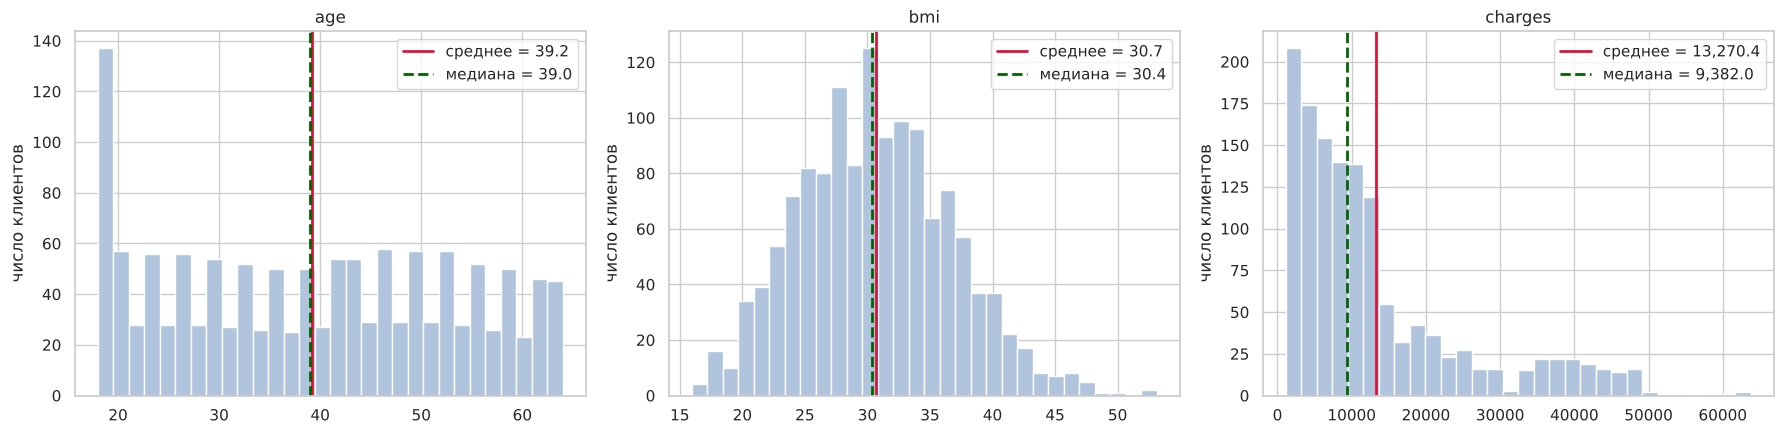

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, c in zip(axes, cols):
    ax.hist(df[c], bins=30, color="lightsteelblue", edgecolor="white")
    ax.axvline(df[c].mean(), color="crimson", lw=2, label=f"среднее = {df[c].mean():,.1f}")
    ax.axvline(df[c].median(), color="darkgreen", lw=2, ls="--", label=f"медиана = {df[c].median():,.1f}")
    ax.set_title(c)
    ax.set_ylabel("число клиентов")
    ax.legend()
plt.tight_layout()
plt.show()

In [8]:
c = 1 / 1000
df["charges_k"] = df.charges * c

mean_charges = df.charges.mean()
mean_k_by_property = c * mean_charges          # M(x*c) = c * M(x), без пересчёта по данным
mean_k_direct = df.charges_k.mean()            # только для проверки

print(f"Среднее charges           = {mean_charges:,.4f} USD")
print(f"По свойству c * M_x       = {mean_k_by_property:.6f} тыс. USD")
print(f"Проверка (прямой расчёт)  = {mean_k_direct:.6f} тыс. USD")
print("Совпадают:", np.isclose(mean_k_by_property, mean_k_direct))

Среднее charges           = 13,270.4223 USD
По свойству c * M_x       = 13.270422 тыс. USD
Проверка (прямой расчёт)  = 13.270422 тыс. USD
Совпадают: True


**Вывод (какую меру и почему для каждой переменной):**

- **`age`** — среднее 39.2, медиана 39, мода 18 (самая частая отдельная группа — 18–19-летние, их заметно больше, чем любого другого возраста). В остальном распределение почти равномерное в диапазоне 18–64 и практически симметричное (skew ≈ 0.06), поэтому среднее и медиана совпадают. Мода здесь вводит в заблуждение (клиент не «типично 18-летний»). **Для слайда — медиана/среднее: «половина клиентов моложе 39 лет»**; лучше дополнить фразой, что база равномерно покрывает все возрасты от 18 до 64.
- **`bmi`** — среднее 30.7, медиана 30.4, мода 32.3. Распределение близко к нормальному, с лёгкой правой асимметрией (skew ≈ 0.28) и небольшим хвостом до 53. Среднее и медиана почти равны, **для слайда подходит среднее (≈ 30.7)** — и это важный факт сам по себе: средний клиент формально находится на границе ожирения (BMI ≥ 30).
- **`charges`** — среднее 13 270 USD, медиана 9 382 USD, мода — одно из уникальных значений (суммы почти не повторяются, поэтому мода бессмысленна). Распределение **сильно скошено вправо** (skew ≈ 1.5), с длинным хвостом до 63 770 USD и видимыми «горбами» в районе 20–25 тыс. и 35–48 тыс. (это курильщики — несколько мод). Среднее завышено хвостом дорогих клиентов на ~40% относительно медианы. **Для слайда «типичный клиент» — медиана (≈ 9 400 USD)**: так тратится на половину клиентов. Но **для бюджета** нужно именно **среднее** (13 270 USD), т.к. общий объём выплат = среднее × число клиентов. На слайде лучше показать обе цифры и объяснить разницу.
- Свойство среднего подтверждено: при делении всех выплат на 1000 среднее стало 13.27 тыс. USD — ровно в 1000 раз меньше, без пересчёта по данным ($M_{x \cdot c} = c \cdot M_x$).

## Задание 4. Насколько клиенты разные: меры изменчивости

Финансовый отдел утверждает: «Курильщики — это предсказуемый сегмент, они просто дороже». PM сомневается: дороже — да, но **предсказуемее ли**?

**4.1.** Разбейте клиентов на две группы по `smoker`. Для `charges` в каждой группе посчитайте: размах ($R$), дисперсию ($D$, `ddof=1`), стандартное отклонение ($sd$, `ddof=1`). Не забудьте про поправку $n-1$ — объясните в одном предложении, почему она нужна.

**4.2.** Посчитайте те же показатели **вручную** по формулам из лекции для группы курильщиков (через цикл или векторно: отклонения от среднего → квадраты → сумма → деление на $n-1$ → корень) и убедитесь, что результат совпадает с `np.var` / `np.std`.

**4.3.** Свойство дисперсии. В следующем году все выплаты вырастут на фиксированную величину 500 USD (индексация). Как изменятся $D$ и $sd$ для `charges`? А если выплаты вырастут на 10% (умножение на 1.1)? Ответьте сначала **по свойствам**, затем проверьте кодом.

**4.4.** Ответьте PM: какой сегмент более однородный по выплатам — курильщики или некурящие? Что это значит для планирования бюджета?

In [9]:
def variability(x):
    return pd.Series({
        "n": len(x),
        "Среднее": x.mean(),
        "Размах R": x.max() - x.min(),
        "Дисперсия D (ddof=1)": np.var(x, ddof=1),
        "sd (ddof=1)": np.std(x, ddof=1),
        "Коэф. вариации sd/mean": np.std(x, ddof=1) / x.mean(),
    })

var_table = df.groupby("smoker").charges.apply(variability).unstack()
var_table.round(2)

,n,Среднее,Размах R,Дисперсия D (ddof=1),sd (ddof=1),Коэф. вариации sd/mean
smoker,,,,,,
no,1064.0,8434.27,35788.73,3.592542e+07,5993.78,0.71
yes,274.0,32050.23,50940.97,1.332073e+08,11541.55,0.36


In [10]:
x = df.loc[df.smoker == "yes", "charges"].to_numpy()
n = len(x)
mean_manual = x.sum() / n
deviations = x - mean_manual            # отклонения от среднего
squares = deviations ** 2               # квадраты отклонений
ss = squares.sum()                      # сумма квадратов
D_manual = ss / (n - 1)                 # дисперсия с поправкой n-1
sd_manual = math.sqrt(D_manual)         # стандартное отклонение
R_manual = x.max() - x.min()

print(f"n = {n}, R = {R_manual:,.2f}")
print(f"Вручную:  D = {D_manual:,.4f}, sd = {sd_manual:,.4f}")
print(f"numpy:    D = {np.var(x, ddof=1):,.4f}, sd = {np.std(x, ddof=1):,.4f}")
print("Совпадают:", np.isclose(D_manual, np.var(x, ddof=1)), np.isclose(sd_manual, np.std(x, ddof=1)))

n = 274, R = 50,940.97
Вручную:  D = 133,207,311.2063, sd = 11,541.5472
numpy:    D = 133,207,311.2063, sd = 11,541.5472
Совпадают: True True


In [11]:
ch = df.charges
D0, sd0 = ch.var(ddof=1), ch.std(ddof=1)

res = pd.DataFrame({
    "D": [D0, (ch + 500).var(ddof=1), (ch * 1.1).var(ddof=1)],
    "sd": [sd0, (ch + 500).std(ddof=1), (ch * 1.1).std(ddof=1)],
    "Ожидание по свойствам: D": [D0, D0, 1.1 ** 2 * D0],
    "Ожидание по свойствам: sd": [sd0, sd0, 1.1 * sd0],
}, index=["исходные", "+500 USD", "×1.1"])
print("D(+500) == D:", np.isclose(res.loc["+500 USD", "D"], D0))
print("D(×1.1) / D =", round(res.loc["×1.1", "D"] / D0, 6), " (ожидаем 1.21)")
print("sd(×1.1) / sd =", round(res.loc["×1.1", "sd"] / sd0, 6), " (ожидаем 1.1)")
res.round(2)

D(+500) == D: True
D(×1.1) / D = 1.21  (ожидаем 1.21)
sd(×1.1) / sd = 1.1  (ожидаем 1.1)


,D,sd,Ожидание по свойствам: D,Ожидание по свойствам: sd
исходные,1.466524e+08,12110.01,1.466524e+08,12110.01
+500 USD,1.466524e+08,12110.01,1.466524e+08,12110.01
×1.1,1.774494e+08,13321.01,1.774494e+08,13321.01


**Вывод:**

**Почему $n-1$:** выборочное среднее «подстроено» под те же данные, поэтому отклонения от него в сумме получаются систематически меньше, чем от истинного среднего ГС; деление на $n-1$ (а не на $n$) убирает это смещение и даёт несмещённую оценку дисперсии генеральной совокупности.

| | Некурящие (n=1064) | Курильщики (n=274) |
|---|---|---|
| Среднее | 8 434 USD | 32 050 USD |
| Размах R | 35 789 USD | 50 941 USD |
| sd | 5 994 USD | 11 542 USD |
| sd / среднее | **0.71** | **0.36** |

Ручной расчёт D и sd для курильщиков полностью совпал с `np.var`/`np.std` (ddof=1).

**Свойства дисперсии (4.3):** при индексации на +500 USD все значения сдвигаются одинаково, расстояния до среднего не меняются → **D и sd не меняются** ($D_{x+c} = D_x$). При росте на 10% все отклонения растут в 1.1 раза → **sd вырастет в 1.1 раза, D — в 1.21 раза** ($D_{x \cdot c} = c^2 D_x$). Код это подтвердил.

**Ответ PM (4.4):** в абсолютных цифрах курильщики разбросаны сильнее (sd 11.5 тыс. против 6.0 тыс., размах 51 тыс. против 36 тыс.), так что утверждение «курильщики предсказуемы» в долларах **неверно**: ошибка прогноза на одного курильщика примерно вдвое больше. Но относительно своего среднего курильщики однороднее (sd ≈ 36% среднего против 71% у некурящих): почти все они дорогие, тогда как некурящие — смесь очень дешёвых и иногда дорогих клиентов. Для бюджета это значит: на сегмент курильщиков нужно закладывать **больший абсолютный резерв** (каждый лишний курильщик — это ±11.5 тыс. USD неопределённости), а внутри курильщиков полезно искать дополнительный фактор, объясняющий разброс (по заданию 5 видно, что это BMI).

## Задание 5. Аномально дорогие клиенты: квартили, IQR, box plot

PM: «Есть ощущение, что несколько клиентов «съедают» весь бюджет. Сколько их на самом деле и кто они?»

**5.1.** Для `charges` посчитайте $Q1$, $Q2$ (медиану), $Q3$ и $IQR$ (`np.percentile` или `df.charges.quantile`).

**5.2.** По алгоритму из лекции вычислите границы выбросов: $Q1 - 1.5 \cdot IQR$ и $Q3 + 1.5 \cdot IQR$. Посчитайте, **сколько клиентов** попадают в выбросы и **какую долю** от всех выплат компании они составляют.

**5.3.** Постройте box plot `charges` по группам `smoker` (`sns.boxplot(x="smoker", y="charges", data=df)`), а затем — по `region`. Опишите, что видно.

**5.4.** Посмотрите на «выбросы» из п. 5.2: какая среди них доля курильщиков? Какой у них средний `bmi`? Сравните с базой в целом.

**5.5.** Ответьте PM: это действительно аномалии (ошибки данных, которые надо удалить) или это **закономерный сегмент**? Что вы рекомендуете: удалять их из анализа, анализировать отдельно или оставить как есть? Обоснуйте.

In [12]:
Q1, Q2, Q3 = np.percentile(df.charges, [25, 50, 75])
IQR = Q3 - Q1
low, high = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
print(f"Q1 = {Q1:,.2f}, Q2 (медиана) = {Q2:,.2f}, Q3 = {Q3:,.2f}, IQR = {IQR:,.2f}")
print(f"Границы выбросов: [{low:,.2f}; {high:,.2f}]  (нижняя < 0, поэтому выбросы только сверху)")

is_out = (df.charges < low) | (df.charges > high)
outliers = df[is_out]
print(f"\nКлиентов-выбросов: {len(outliers)} из {len(df)} ({len(outliers) / len(df):.1%})")
print(f"Их доля в сумме всех выплат: {outliers.charges.sum() / df.charges.sum():.1%} "
      f"({outliers.charges.sum():,.0f} из {df.charges.sum():,.0f} USD)")

Q1 = 4,740.29, Q2 (медиана) = 9,382.03, Q3 = 16,639.91, IQR = 11,899.63
Границы выбросов: [-13,109.15; 34,489.35]  (нижняя < 0, поэтому выбросы только сверху)

Клиентов-выбросов: 139 из 1338 (10.4%)
Их доля в сумме всех выплат: 33.0% (5,852,449 из 17,755,825 USD)


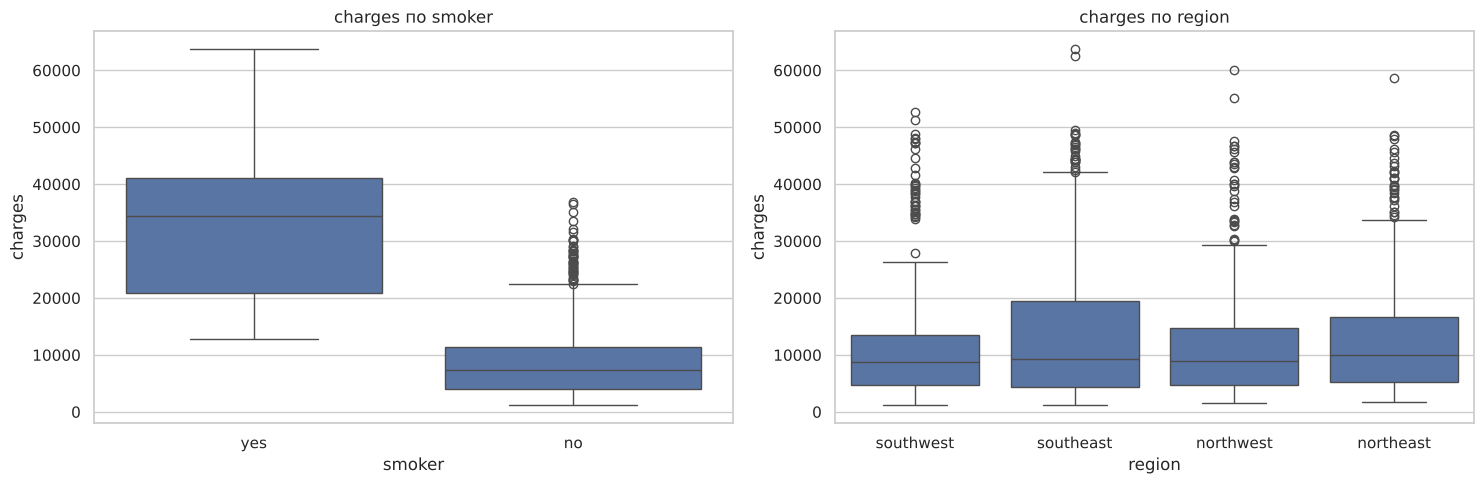

,count,mean,25%,50%,75%,max
region,,,,,,
northeast,324.0,13406.0,5194.0,10058.0,16687.0,58571.0
northwest,325.0,12418.0,4720.0,8966.0,14712.0,60021.0
southeast,364.0,14735.0,4441.0,9294.0,19526.0,63770.0
southwest,325.0,12347.0,4751.0,8799.0,13463.0,52591.0


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(x="smoker", y="charges", data=df, ax=axes[0])
axes[0].set_title("charges по smoker")
sns.boxplot(x="region", y="charges", data=df, ax=axes[1])
axes[1].set_title("charges по region")
plt.tight_layout()
plt.show()

df.groupby("region").charges.describe()[["count", "mean", "25%", "50%", "75%", "max"]].round(0)

In [14]:
portrait = pd.DataFrame({
    "Выбросы": [len(outliers), (outliers.smoker == "yes").mean(), outliers.bmi.mean(),
                (outliers.bmi >= 30).mean(), outliers.age.mean(), outliers.charges.mean()],
    "Вся база": [len(df), (df.smoker == "yes").mean(), df.bmi.mean(),
                 (df.bmi >= 30).mean(), df.age.mean(), df.charges.mean()],
}, index=["n", "Доля курильщиков", "Средний BMI", "Доля BMI ≥ 30", "Средний возраст", "Средние charges"])
display(portrait.round(3))

print("Выбросы по регионам:")
print(outliers.region.value_counts())

,Выбросы,Вся база
n,139.000,1338.000
Доля курильщиков,0.978,0.205
Средний BMI,35.565,30.663
Доля BMI ≥ 30,0.964,0.528
Средний возраст,41.079,39.207
Средние charges,42103.947,13270.422


Выбросы по регионам:
region
southeast    57
southwest    34
northeast    28
northwest    20
Name: count, dtype: int64


**Вывод:**

- Квартили `charges`: Q1 ≈ 4 740, медиана ≈ 9 382, Q3 ≈ 16 640 USD, IQR ≈ 11 900 USD. Верхняя граница выбросов — **≈ 34 489 USD** (нижняя отрицательная, т.е. выбросов снизу нет).
- Выше границы — **139 клиентов (10.4% базы)**, и они дают **≈ 33% всех выплат** компании. Ощущение PM верное: примерно каждый десятый клиент «съедает» треть бюджета.
- **Box plot по `smoker`:** «ящики» курящих и некурящих практически не пересекаются — медиана курильщиков (~34.5 тыс.) выше максимума «усов» некурящих. У некурящих при этом много точек‑выбросов сверху (дорогие некурящие — вероятно, хронические болезни/возраст). У курильщиков выбросов почти нет: их высокие выплаты — норма для этого сегмента.
- **Box plot по `region`:** регионы очень похожи — медианы 8.8–10.1 тыс., у всех длинный верхний хвост. Немного выделяется `southeast`: у него шире ящик и выше Q3 и среднее (14.7 тыс.), что согласуется с гипотезой D.
- **Портрет выбросов:** **97.8% из них — курильщики** (против 20.5% в базе), средний BMI ≈ **35.6** (против 30.7 в базе); почти все они с ожирением. То есть «аномально дорогой клиент» = курильщик с BMI ≥ 30.

**Рекомендация (5.5):** это **не ошибки данных, а закономерный сегмент** — значения правдоподобны и полностью объясняются комбинацией «курение + ожирение». Удалять их нельзя: мы потеряем треть реальных расходов и занизим бюджет. Правильно — **анализировать их отдельно как сегмент** (курящие с высоким BMI) с собственным тарифом и резервом, а в общих расчётах бюджета оставить как есть; для описания «типичного» клиента использовать медиану и устойчивые меры.

## Задание 6. Нормальное распределение, z-оценки и правило 2–3 сигм

Отдел андеррайтинга хочет ввести **надбавку за высокий BMI**: «клиенты с BMI выше 40 — редкость, их можно оценивать индивидуально». Нужно проверить, насколько это редкость.

**6.1.** Постройте гистограмму `bmi` и наложите на неё кривую плотности нормального распределения с параметрами $\mu = \bar{X}_{bmi}$, $\sigma = sd_{bmi}$ (`stats.norm.pdf`). Похоже ли распределение на нормальное «на глаз»?

**6.2.** Выполните **z-стандартизацию** колонки `bmi` (создайте колонку `bmi_z`). Убедитесь, что новое среднее $\approx 0$, а стандартное отклонение $\approx 1$. Форма гистограммы изменилась?

**6.3.** Клиент с ID = 1317 (последняя строка таблицы, `df.iloc[-1]`) — какова его z-оценка по `bmi`? На сколько стандартных отклонений он отличается от среднего клиента и в какую сторону?

**6.4.** Используя нормальную модель ($\mu$, $\sigma$ из п. 6.1) и `stats.norm.sf` / `.cdf`, посчитайте **теоретическую** долю клиентов с `bmi > 40`. Затем посчитайте **фактическую** долю по данным. Насколько они расходятся?

**6.5.** По правилу 2–3 сигм посчитайте, сколько клиентов должны лежать в интервале $[\mu - 2\sigma; \mu + 2\sigma]$ (ожидается $\approx 95.4\%$), и сравните с фактом.

**6.6.** Ответьте отделу андеррайтинга: справедливо ли утверждение «BMI > 40 — редкость»? Какой порог вы бы предложили, если «редкостью» считать верхние 5% клиентов (подсказка: `stats.norm.isf(0.05, mu, sigma)` и `df.bmi.quantile(0.95)` — сравните оба варианта).

mu = 30.663, sigma = 6.098


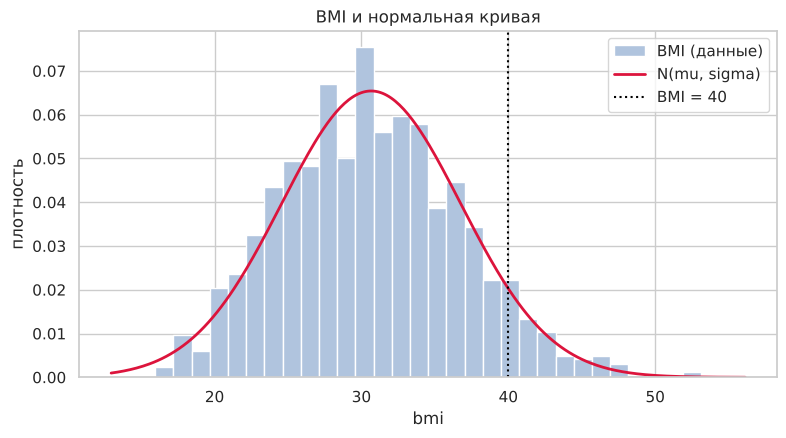

In [15]:
mu_bmi = df.bmi.mean()
sd_bmi = df.bmi.std(ddof=1)
print(f"mu = {mu_bmi:.3f}, sigma = {sd_bmi:.3f}")

xs = np.linspace(df.bmi.min() - 3, df.bmi.max() + 3, 300)
plt.figure(figsize=(9, 4.5))
plt.hist(df.bmi, bins=30, density=True, color="lightsteelblue", edgecolor="white", label="BMI (данные)")
plt.plot(xs, stats.norm.pdf(xs, mu_bmi, sd_bmi), color="crimson", lw=2, label="N(mu, sigma)")
plt.axvline(40, color="black", ls=":", label="BMI = 40")
plt.xlabel("bmi"); plt.ylabel("плотность"); plt.legend(); plt.title("BMI и нормальная кривая")
plt.show()

Среднее bmi_z = -2.12e-16, sd bmi_z = 1.0000


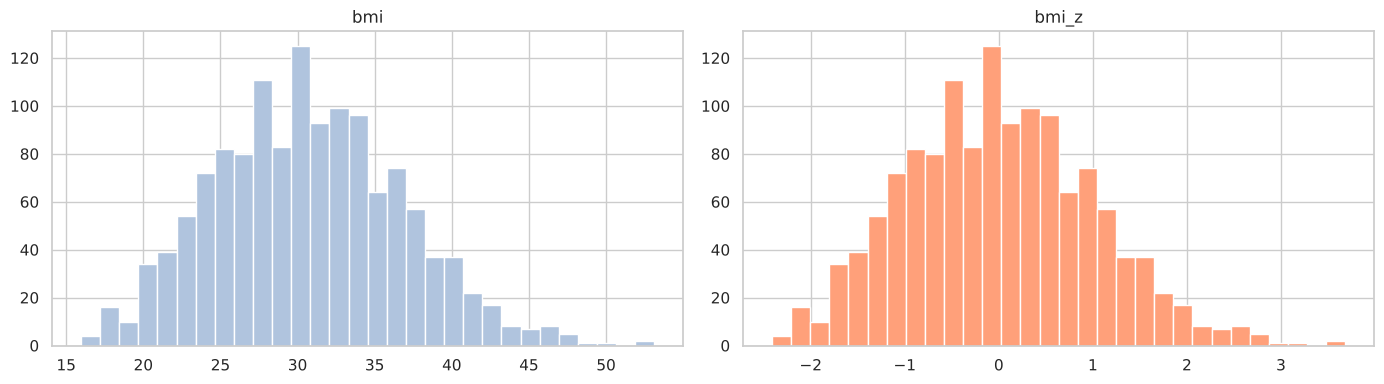

In [16]:
df["bmi_z"] = (df.bmi - mu_bmi) / sd_bmi
print(f"Среднее bmi_z = {df.bmi_z.mean():.2e}, sd bmi_z = {df.bmi_z.std(ddof=1):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df.bmi, bins=30, color="lightsteelblue", edgecolor="white"); axes[0].set_title("bmi")
axes[1].hist(df.bmi_z, bins=30, color="lightsalmon", edgecolor="white"); axes[1].set_title("bmi_z")
plt.tight_layout(); plt.show()

In [17]:
last = df.iloc[-1]
z_last = (last.bmi - mu_bmi) / sd_bmi
print(last[["age", "sex", "bmi", "children", "smoker", "region", "charges"]])
print(f"\nz-оценка по bmi: {z_last:.3f} (то же в bmi_z: {df.bmi_z.iloc[-1]:.3f})")
print(f"Клиент на {abs(z_last):.2f} sd {'ниже' if z_last < 0 else 'выше'} среднего BMI")

age                 61
sex             female
bmi              29.07
children             0
smoker             yes
region       northwest
charges     29141.3603
Name: 1337, dtype: object

z-оценка по bmi: -0.261 (то же в bmi_z: -0.261)
Клиент на 0.26 sd ниже среднего BMI


In [18]:
# 6.4 доля bmi > 40
p_theor = stats.norm.sf(40, mu_bmi, sd_bmi)
p_fact = (df.bmi > 40).mean()
print(f"bmi > 40: теоретически {p_theor:.2%} (~{p_theor * len(df):.0f} чел.), "
      f"фактически {p_fact:.2%} ({(df.bmi > 40).sum()} чел.); разница {p_fact - p_theor:+.2%}")

# 6.5 правило 2 и 3 сигм
for k, expected in [(1, 0.6827), (2, 0.9545), (3, 0.9973)]:
    inside = df.bmi.between(mu_bmi - k * sd_bmi, mu_bmi + k * sd_bmi).mean()
    print(f"[mu ± {k} sigma] = [{mu_bmi - k * sd_bmi:.2f}; {mu_bmi + k * sd_bmi:.2f}]: "
          f"факт {inside:.2%}, по нормальному закону {expected:.2%}, "
          f"т.е. ~{expected * len(df):.0f} чел. ожидается, {int(inside * len(df))} фактически")

# 6.6 порог верхних 5%
thr_norm = stats.norm.isf(0.05, mu_bmi, sd_bmi)
thr_emp = df.bmi.quantile(0.95)
print(f"\nПорог верхних 5%: по нормальной модели {thr_norm:.2f}, по данным (95-й перцентиль) {thr_emp:.2f}")

bmi > 40: теоретически 6.29% (~84 чел.), фактически 6.80% (91 чел.); разница +0.51%
[mu ± 1 sigma] = [24.57; 36.76]: факт 66.97%, по нормальному закону 68.27%, т.е. ~913 чел. ожидается, 896 фактически
[mu ± 2 sigma] = [18.47; 42.86]: факт 95.74%, по нормальному закону 95.45%, т.е. ~1277 чел. ожидается, 1281 фактически
[mu ± 3 sigma] = [12.37; 48.96]: факт 99.70%, по нормальному закону 99.73%, т.е. ~1334 чел. ожидается, 1334 фактически

Порог верхних 5%: по нормальной модели 40.69, по данным (95-й перцентиль) 41.11


**Вывод:**

- **6.1.** Распределение BMI на глаз хорошо описывается нормальной кривой ($\mu \approx 30.66$, $\sigma \approx 6.10$): один пик около 30, почти симметричное, с чуть более тяжёлым правым хвостом (skew ≈ 0.28).
- **6.2.** После z-стандартизации среднее ≈ 0 (порядка $10^{-16}$), sd = 1; **форма гистограммы не изменилась** — z-преобразование линейно, оно лишь сдвигает и масштабирует ось.
- **6.3.** Последний клиент (61 год, курящая женщина, northwest, BMI 29.07): **z ≈ −0.26**, т.е. её BMI на 0.26 стандартного отклонения **ниже** среднего — абсолютно типичное значение.
- **6.4.** Нормальная модель даёт **≈ 6.3%** клиентов с BMI > 40 (~84 чел.), фактически их **6.8% (91 чел.)**. Расхождение небольшое (+0.5 п.п.) и объясняется немного более тяжёлым правым хвостом реальных данных.
- **6.5.** В интервале $\mu \pm 2\sigma$ = [18.47; 42.86] фактически **95.7%** клиентов при теоретических 95.4%; в $\mu \pm 3\sigma$ — 99.7% (как и по теории). Правило 2–3 сигм выполняется очень хорошо.

**Ответ андеррайтингу (6.6):** BMI > 40 — это **около 7% клиентов (91 человек)**, т.е. каждый ~15-й. Это не «единичные случаи»: индивидуальная оценка 91 клиента — заметная нагрузка, но назвать их «редкостью» в строгом смысле (верхние 5%) нельзя. Если «редкость» = верхние 5%, порог должен быть **≈ 40.7 по нормальной модели** или **≈ 41.1 по реальному 95-му перцентилю**. Рекомендую опираться на **эмпирический порог ≈ 41** (данные чуть тяжелее нормального хвоста, и перцентиль не зависит от предположения о форме распределения). Округлённо: порог 40 охватывает ~7%, порог 41 — ровно ~5% клиентов.

## Задание 7. Центральная предельная теорема на наших данных

Распределение `charges` (задание 3) явно не нормальное. PM спрашивает: «Тогда как вы вообще собираетесь доверять среднему по выборке?» Ответ на это — ЦПТ. Покажите её на практике.

Снова считаем таблицу из 1 338 клиентов **генеральной совокупностью**.

**7.1.** Извлеките из ГС **1000 выборок** по $n = 50$ клиентов каждая (с возвращением, `df.charges.sample(n=50, replace=True)` в цикле) и для каждой посчитайте среднее `charges`. Постройте гистограмму 1000 выборочных средних.

**7.2.** Сравните:
- среднее ГС и среднее выборочных средних;
- стандартное отклонение выборочных средних (это и есть эмпирическая $se$) и теоретическую $se = \dfrac{sd_{ГС}}{\sqrt{n}}$.

**7.3.** Повторите п. 7.1 для $n = 10$ и $n = 200$. Постройте три гистограммы рядом (одинаковая ось X). Как меняется форма и ширина распределения выборочных средних?

**7.4.** Ответьте PM в 2–3 предложениях: почему мы можем использовать среднее выборки и доверительные интервалы, даже если сами выплаты распределены сильно асимметрично? От чего зависит точность?

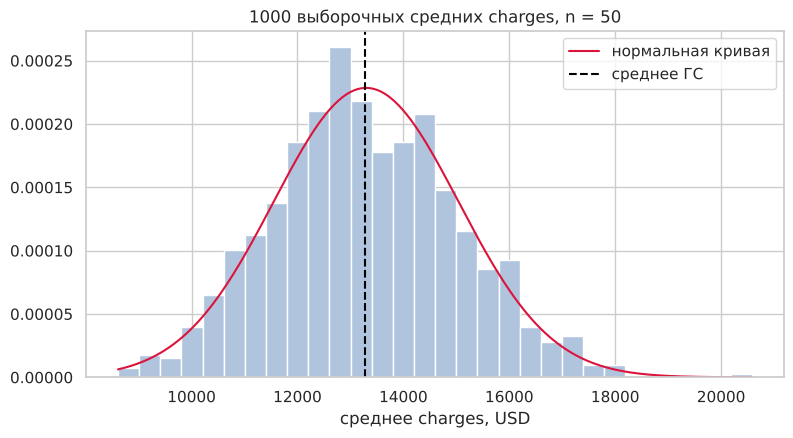

In [19]:
def sample_means(n, n_samples=1000):
    return np.array([df.charges.sample(n=n, replace=True).mean() for _ in range(n_samples)])

means_50 = sample_means(50)

plt.figure(figsize=(9, 4.5))
plt.hist(means_50, bins=30, color="lightsteelblue", edgecolor="white", density=True)
xs = np.linspace(means_50.min(), means_50.max(), 300)
plt.plot(xs, stats.norm.pdf(xs, means_50.mean(), means_50.std(ddof=1)), color="crimson", label="нормальная кривая")
plt.axvline(df.charges.mean(), color="black", ls="--", label="среднее ГС")
plt.title("1000 выборочных средних charges, n = 50"); plt.xlabel("среднее charges, USD"); plt.legend()
plt.show()

In [20]:
mu_gs = df.charges.mean()
sd_gs = df.charges.std(ddof=0)  # ГС: вся таблица — генеральная совокупность
se_theor = sd_gs / np.sqrt(50)
se_emp = means_50.std(ddof=1)

print(f"Среднее ГС:                   {mu_gs:,.1f}")
print(f"Среднее выборочных средних:   {means_50.mean():,.1f}  (разница {means_50.mean() - mu_gs:+,.1f})")
print(f"Эмпирическая se (sd средних): {se_emp:,.1f}")
print(f"Теоретическая se = sd/sqrt(n): {se_theor:,.1f}  (отношение {se_emp / se_theor:.3f})")
print(f"Асимметрия: исходные charges {df.charges.skew():.2f}, выборочные средние {pd.Series(means_50).skew():.2f}")

Среднее ГС:                   13,270.4
Среднее выборочных средних:   13,295.7  (разница +25.2)
Эмпирическая se (sd средних): 1,746.0
Теоретическая se = sd/sqrt(n): 1,712.0  (отношение 1.020)
Асимметрия: исходные charges 1.52, выборочные средние 0.16


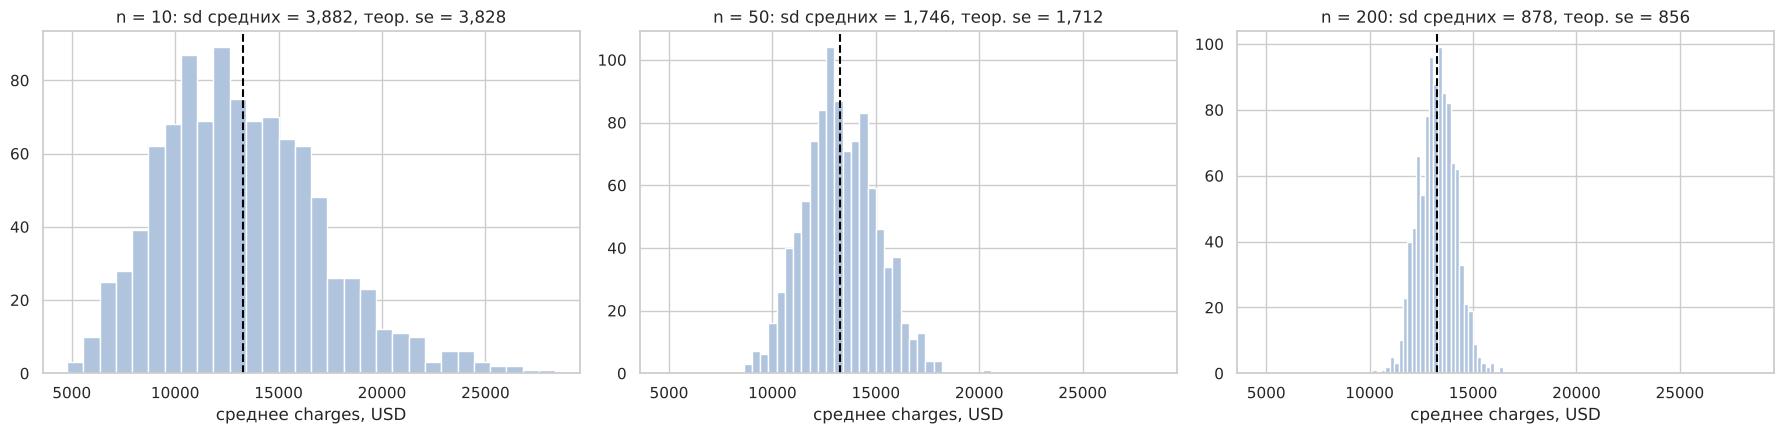

,10,50,200
среднее средних,13231.84,13295.66,13253.25
эмп. se,3881.80,1746.02,877.54
теор. se,3828.09,1711.97,855.99
skew,0.60,0.16,0.09


In [21]:
ns = [10, 50, 200]
all_means = {10: sample_means(10), 50: means_50, 200: sample_means(200)}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharex=True)
for ax, n in zip(axes, ns):
    m = all_means[n]
    ax.hist(m, bins=30, color="lightsteelblue", edgecolor="white")
    ax.axvline(mu_gs, color="black", ls="--")
    ax.set_title(f"n = {n}: sd средних = {m.std(ddof=1):,.0f}, теор. se = {sd_gs / np.sqrt(n):,.0f}")
    ax.set_xlabel("среднее charges, USD")
plt.tight_layout(); plt.show()

pd.DataFrame({n: {"среднее средних": all_means[n].mean(), "эмп. se": all_means[n].std(ddof=1),
                  "теор. se": sd_gs / np.sqrt(n), "skew": pd.Series(all_means[n]).skew()} for n in ns}).round(2)

**Вывод:**

- Хотя сами выплаты сильно скошены (skew ≈ 1.5), гистограмма 1000 выборочных средних при n = 50 уже имеет почти нормальную колоколообразную форму с центром в среднем ГС (13 270 USD): среднее выборочных средних отличается от него лишь на десятки долларов.
- Эмпирическая se (sd выборочных средних) практически совпадает с теоретической $sd_{ГС}/\sqrt{n} \approx 1\,712$ USD при n = 50.
- При n = 10 распределение средних ещё заметно скошено вправо и очень широкое (se ≈ 3 800 USD); при n = 50 — почти симметричное; при n = 200 — узкое (se ≈ 860 USD) и практически нормальное. Ширина падает пропорционально $1/\sqrt{n}$: увеличение выборки в 4 раза сужает разброс вдвое.

**Ответ PM (7.4):** по центральной предельной теореме среднее достаточно большой выборки распределено почти нормально вокруг истинного среднего, **какой бы асимметричной ни была исходная величина** — поэтому для средней выплаты можно строить доверительные интервалы и z-тесты. Точность оценки определяется стандартной ошибкой $se = sd/\sqrt{n}$: она тем меньше, чем **больше выборка** и чем **однороднее клиенты** (меньше sd); при сильно скошенных данных, как у нас, нужна выборка хотя бы в несколько десятков, а лучше сотен клиентов.

## Задание 8. Доверительные интервалы для бюджета

Финансовый отдел планирует резерв на выплаты. Им нужна не одна цифра, а **диапазон**, в котором с высокой уверенностью лежит средняя выплата на клиента.

**8.1.** Возьмите одну случайную выборку из $n = 100$ клиентов (`random_state=1`). Посчитайте $\bar{X}$, $sd$, $se = sd / \sqrt{n}$ для `charges`.

**8.2.** Постройте **95%** и **99%** доверительные интервалы для среднего `charges`. Коэффициенты 1.96 и 2.58 получите через `stats.norm.isf`, как в лекции, а не «из головы».

**8.3.** Проверьте: попадает ли **истинное** среднее ГС (по всем 1 338 клиентам) в ваши интервалы?

**8.4.** Финансовый отдел готов оплатить сбор данных ещё по 300 клиентам (итого $n = 400$). Не пересчитывая ничего по данным, только через формулу $se$, скажите: во сколько раз сузится 95% ДИ? Затем проверьте на реальной выборке из 400 клиентов.

**8.5.** Постройте 95% ДИ для среднего `charges` **отдельно для курильщиков и некурящих** (по всей базе). Пересекаются ли интервалы? Что это говорит PM ещё до всяких формальных тестов?

**8.6.** Напишите одну фразу для финансового отдела в формате: «С уверенностью 95% средняя выплата на клиента лежит в диапазоне от … до … USD», и объясните в одном предложении, что именно означает «95%» (вспомните вопрос из лекции про правильную интерпретацию ДИ).

In [22]:
s100 = df.charges.sample(n=100, random_state=1)
n100 = len(s100)
X_ = s100.mean()
sd100 = s100.std(ddof=1)
se100 = sd100 / np.sqrt(n100)
print(f"n = {n100}, X_ = {X_:,.2f}, sd = {sd100:,.2f}, se = {se100:,.2f}")

n = 100, X_ = 14,859.44, sd = 12,770.68, se = 1,277.07


In [23]:
true_mean = df.charges.mean()
ci = {}
for conf in [0.95, 0.99]:
    z_crit = stats.norm.isf((1 - conf) / 2)
    lo, hi = X_ - z_crit * se100, X_ + z_crit * se100
    ci[conf] = (lo, hi)
    print(f"{conf:.0%} ДИ: z = {z_crit:.4f}, [{lo:,.2f}; {hi:,.2f}], ширина {hi - lo:,.0f}; "
          f"среднее ГС {true_mean:,.2f} внутри: {lo <= true_mean <= hi}")

95% ДИ: z = 1.9600, [12,356.44; 17,362.45], ширина 5,006; среднее ГС 13,270.42 внутри: True
99% ДИ: z = 2.5758, [11,569.93; 18,148.95], ширина 6,579; среднее ГС 13,270.42 внутри: True


In [24]:
z95 = stats.norm.isf(0.025)
print(f"По формуле: se ~ 1/sqrt(n) -> ширина ДИ сократится в sqrt(400/100) = {np.sqrt(400 / 100):.0f} раза")

s400 = df.charges.sample(n=400, random_state=1)
se400 = s400.std(ddof=1) / np.sqrt(400)
lo400, hi400 = s400.mean() - z95 * se400, s400.mean() + z95 * se400
w100 = ci[0.95][1] - ci[0.95][0]
w400 = hi400 - lo400
print(f"n = 100: 95% ДИ [{ci[0.95][0]:,.0f}; {ci[0.95][1]:,.0f}], ширина {w100:,.0f}")
print(f"n = 400: 95% ДИ [{lo400:,.0f}; {hi400:,.0f}], ширина {w400:,.0f}")
print(f"Фактическое сужение: в {w100 / w400:.2f} раза (отличие от 2 — из-за разных sd двух выборок)")
print(f"Среднее ГС {true_mean:,.0f} внутри ДИ (n=400): {lo400 <= true_mean <= hi400}")

По формуле: se ~ 1/sqrt(n) -> ширина ДИ сократится в sqrt(400/100) = 2 раза
n = 100: 95% ДИ [12,356; 17,362], ширина 5,006
n = 400: 95% ДИ [12,045; 14,383], ширина 2,338
Фактическое сужение: в 2.14 раза (отличие от 2 — из-за разных sd двух выборок)
Среднее ГС 13,270 внутри ДИ (n=400): True


,n,mean,se,ci_low,ci_high
no,1064.0,8434.27,183.75,8074.12,8794.41
yes,274.0,32050.23,697.25,30683.65,33416.82


Интервалы пересекаются: False


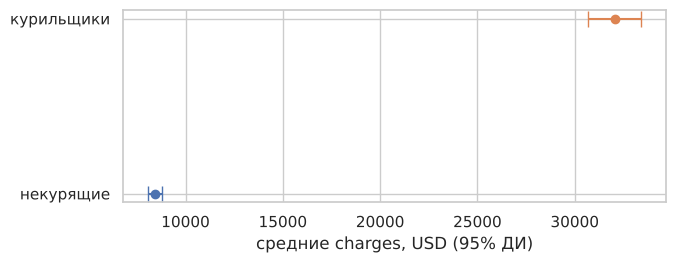

In [25]:
rows = {}
for grp, x in df.groupby("smoker").charges:
    se_g = x.std(ddof=1) / np.sqrt(len(x))
    rows[grp] = {"n": len(x), "mean": x.mean(), "se": se_g,
                 "ci_low": x.mean() - z95 * se_g, "ci_high": x.mean() + z95 * se_g}
ci_smoker = pd.DataFrame(rows).T
display(ci_smoker.round(2))
print("Интервалы пересекаются:", ci_smoker.loc["no", "ci_high"] >= ci_smoker.loc["yes", "ci_low"])

plt.figure(figsize=(7, 2.5))
for i, grp in enumerate(["no", "yes"]):
    r = ci_smoker.loc[grp]
    plt.errorbar(r["mean"], i, xerr=[[r["mean"] - r.ci_low], [r.ci_high - r["mean"]]], fmt="o", capsize=6)
plt.yticks([0, 1], ["некурящие", "курильщики"]); plt.xlabel("средние charges, USD (95% ДИ)")
plt.show()

**Вывод:**

- Случайная выборка n = 100 (random_state=1): $\bar X \approx 14\,859$ USD, $sd \approx 12\,771$, $se \approx 1\,277$ USD.
- Коэффициенты через `stats.norm.isf`: 1.96 (95%) и 2.576 (99%). **95% ДИ: [12 356; 17 362] USD**, **99% ДИ: [11 570; 18 149] USD**. Истинное среднее ГС **13 270 USD попадает в оба** интервала, хотя наша выборка оказалась «дорогой» (точечная оценка завышена на 1 600 USD) — именно поэтому нужен интервал, а не одна цифра. 99% ДИ шире: за бо́льшую уверенность платим точностью.
- **n = 400:** по формуле $se = sd/\sqrt n$ ширина ДИ уменьшится в $\sqrt{4} = 2$ раза. На реальной выборке: ширина ~2 340 USD против ~5 010 USD — сужение в ~2.1 раза (отличие от 2 — потому что sd двух выборок немного разные). ДИ [12 045; 14 383] тоже содержит истинное среднее.
- **Курильщики vs некурящие:** 95% ДИ — некурящие **[8 074; 8 794]**, курильщики **[30 684; 33 417]** USD. Интервалы **не пересекаются, и между ними пропасть в ~22 тыс. USD**. Ещё до формальных тестов PM может уверенно говорить: курильщики в среднем обходятся почти в **4 раза дороже**, и это не случайность выборки.

**Фраза для финансового отдела (по выборке n = 400):** «С уверенностью 95% средняя выплата на клиента лежит в диапазоне **от 12 045 до 14 383 USD**». (По выборке из 100 клиентов тот же интервал был бы 12 356 – 17 362 USD.)

**Что значит «95%»:** это не вероятность того, что истинное среднее лежит именно в этом конкретном интервале, а надёжность метода — если много раз повторять выборку и строить ДИ таким способом, примерно 95% построенных интервалов накроют истинную среднюю выплату.

## Задание 9. Проверка гипотез: что из «общеизвестного» в компании правда?

Это главная часть работы. В компании ходят четыре утверждения; PM хочет по каждому получить чёткий вердикт: **подтверждаем / отклоняем**, с $p$-значением и с доверительным интервалом.

Для каждой гипотезы оформите ответ по единой схеме (как в лекции, раздел «Идея статистического вывода»):

1. Сформулировать $H_0$ и $H_1$ (двусторонняя или односторонняя альтернатива — обосновать).
2. Посчитать $\bar{X}$, $sd$, $n$, $se = sd/\sqrt{n}$.
3. Посчитать $z = \dfrac{\bar{X} - M_0}{se}$.
4. Посчитать $p$-значение (`stats.norm.cdf` / `.sf`; можно использовать функцию `p_value` из лекции — она ниже).
5. Построить 95% ДИ и проверить, попадает ли в него $M_0$ — результаты двух подходов должны согласоваться.
6. Вердикт при $\alpha = 0.05$ и **вывод для бизнеса** одним-двумя предложениями.

---

### Гипотеза A. «Средний курильщик обходится нам в 30 000 USD в год»
Маркетинг использует эту цифру в презентациях уже два года. Проверьте: равна ли средняя выплата по курильщикам $M_0 = 30\,000$ USD? (Альтернатива — двусторонняя: нас интересует любое отклонение.)

### Гипотеза B. «Наша целевая аудитория — клиенты 39 лет»
Продуктовая стратегия построена вокруг «среднего клиента 39 лет». Проверьте: равен ли средний возраст клиентов $M_0 = 39$ годам?

### Гипотеза C. «Северо-восток укладывается в бюджет 12 500 USD на клиента»
Финансы заложили в бюджет региона `northeast` среднюю выплату $M_0 = 12\,500$ USD. Проверьте, есть ли основания считать, что реальная средняя выплата по этому региону отличается от бюджета.

### Гипотеза D. «Юго-восток — проблемный регион, там выплаты выше 13 000 USD»
Руководитель по региону `southeast` просит увеличить бюджет, утверждая, что средняя выплата там **превышает** $M_0 = 13\,000$ USD. Здесь альтернатива **односторонняя** («больше») — объясните, почему это меняет расчёт $p$-значения.

### Гипотеза E (бонус, ваша собственная).
Сформулируйте **своё** утверждение о клиентской базе, которое было бы полезно PM (например, про `bmi`, `children` или другой регион), и проверьте его по той же схеме.

In [26]:
# функция из лекции для расчёта p-значения по z-статистике
def p_value(z_stat, alternative="two-sided"):
    if alternative == "two-sided":
        return 2 * (1 - stats.norm.cdf(np.abs(z_stat)))
    if alternative == "less":
        return stats.norm.cdf(z_stat)
    if alternative == "greater":
        return 1 - stats.norm.cdf(z_stat)


def z_test_mean(sample, m0, alternative="two-sided", conf=0.95):
    '''
    z-критерий для среднего (большая выборка, sigma ГС заменяем на sd выборки).
    Возвращает словарь с n, mean, sd, se, z, p, ci_low, ci_high.
    ДИ — всегда двусторонний (conf), для односторонней альтернативы дополнительно
    возвращается односторонняя граница (ci_one_sided).
    '''
    x = np.asarray(sample, dtype=float)
    n = len(x)
    mean = x.mean()
    sd = x.std(ddof=1)
    se = sd / np.sqrt(n)
    z = (mean - m0) / se
    p = p_value(z, alternative)
    z_crit = stats.norm.isf((1 - conf) / 2)
    res = {"n": n, "mean": mean, "sd": sd, "se": se, "z": z, "p": p,
           "ci_low": mean - z_crit * se, "ci_high": mean + z_crit * se}
    if alternative == "greater":   # односторонняя нижняя граница: mean - z_(alpha) * se
        res["ci_one_sided"] = (mean - stats.norm.isf(1 - conf) * se, np.inf)
    elif alternative == "less":
        res["ci_one_sided"] = (-np.inf, mean + stats.norm.isf(1 - conf) * se)
    return res


def report(res, m0, alpha=0.05):
    for k in ["n", "mean", "sd", "se", "z", "p", "ci_low", "ci_high"]:
        v = res[k]
        print(f"{k:>8}: {v:,.4f}" if k != "p" else f"{k:>8}: {v:.6f}")
    if "ci_one_sided" in res:
        lo, hi = res["ci_one_sided"]
        print(f"односторонний 95% ДИ: [{lo:,.2f}; {hi}]  M0 внутри: {lo <= m0 <= hi}")
    print(f"M0 = {m0:,} внутри двустороннего 95% ДИ: {res['ci_low'] <= m0 <= res['ci_high']}")
    print("Вердикт:", "H0 отклоняем" if res["p"] < alpha else "нет оснований отклонить H0", f"(alpha = {alpha})")

### Гипотеза A — «средний курильщик = 30 000 USD»

- $H_0$: средняя годовая выплата по курильщикам $M = 30\,000$ USD.
- $H_1$: $M \neq 30\,000$ USD (двусторонняя: маркетингу важно знать, верна ли цифра, ошибка в любую сторону искажает презентации и расчёты).

In [27]:
res_A = z_test_mean(df.loc[df.smoker == "yes", "charges"], 30000)
report(res_A, 30000)

       n: 274.0000
    mean: 32,050.2318
      sd: 11,541.5472
      se: 697.2504
       z: 2.9405
       p: 0.003277
  ci_low: 30,683.6462
 ci_high: 33,416.8174
M0 = 30,000 внутри двустороннего 95% ДИ: False
Вердикт: H0 отклоняем (alpha = 0.05)


**Вердикт и вывод для бизнеса:** $n = 274$, $\bar X \approx 32\,050$ USD, $sd \approx 11\,542$, $se \approx 697$; $z \approx 2.94$, $p \approx 0.0033 < 0.05$ → **$H_0$ отклоняем**. 95% ДИ [30 684; 33 417] USD не содержит 30 000 — оба подхода согласуются. Цифра маркетинга **устарела/занижена**: реальная средняя выплата по курильщику примерно **32 тыс. USD** (на ~7% больше). Если тарифы курильщиков привязаны к 30 тыс., компания недополучает около 2 тыс. USD на каждого курильщика — в презентациях и при расчёте надбавки нужно использовать ~32 тыс.

### Гипотеза B — «средний возраст клиента = 39 лет»

- $H_0$: средний возраст клиентов $M = 39$ лет.
- $H_1$: $M \neq 39$ лет (двусторонняя: стратегия ломается при отклонении в любую сторону).

In [28]:
res_B = z_test_mean(df.age, 39)
report(res_B, 39)

       n: 1,338.0000
    mean: 39.2070
      sd: 14.0500
      se: 0.3841
       z: 0.5390
       p: 0.589897
  ci_low: 38.4542
 ci_high: 39.9599
M0 = 39 внутри двустороннего 95% ДИ: True
Вердикт: нет оснований отклонить H0 (alpha = 0.05)


**Вердикт и вывод для бизнеса:** $n = 1338$, $\bar X \approx 39.21$, $sd \approx 14.05$, $se \approx 0.38$; $z \approx 0.54$, $p \approx 0.59 > 0.05$ → **нет оснований отклонить $H_0$**. 95% ДИ [38.45; 39.96] содержит 39. Средний возраст действительно ≈ 39 лет — утверждение **подтверждается** данными. Но важная оговорка для продуктовой стратегии: возраст распределён почти **равномерно** от 18 до 64 (sd ≈ 14 лет), так что «клиент 39 лет» — это статистическое среднее, а не типичный клиент; строить продукт только под 39-летних было бы ошибкой — нужны предложения для всех возрастных групп.

### Гипотеза C — «northeast: средняя выплата = 12 500 USD»

- $H_0$: средняя выплата по региону `northeast` $M = 12\,500$ USD (бюджет верен).
- $H_1$: $M \neq 12\,500$ USD (двусторонняя: вопрос «отличается ли от бюджета», важны и перерасход, и избыточный резерв).

In [29]:
res_C = z_test_mean(df.loc[df.region == "northeast", "charges"], 12500)
report(res_C, 12500)

       n: 324.0000
    mean: 13,406.3845
      sd: 11,255.8031
      se: 625.3224
       z: 1.4495
       p: 0.147207
  ci_low: 12,180.7751
 ci_high: 14,631.9939
M0 = 12,500 внутри двустороннего 95% ДИ: True
Вердикт: нет оснований отклонить H0 (alpha = 0.05)


**Вердикт и вывод для бизнеса:** $n = 324$, $\bar X \approx 13\,406$ USD, $sd \approx 11\,256$, $se \approx 625$; $z \approx 1.45$, $p \approx 0.147 > 0.05$ → **нет оснований отклонить $H_0$**. 95% ДИ [12 181; 14 632] содержит 12 500. Статистически значимого отличия от бюджета нет — бюджет 12 500 USD **не опровергнут**. Однако точечная оценка на ~900 USD выше бюджета, а ДИ широкий и уходит до 14.6 тыс. — финансам стоит заложить запас (например, ориентироваться на ~13.4 тыс.) и перепроверить на данных следующего года: «не отклонили» ≠ «доказали, что ровно 12 500».

### Гипотеза D — «southeast: средняя выплата > 13 000 USD»

- $H_0$: $M \le 13\,000$ USD (выплаты не превышают 13 000; для расчёта используем $M_0 = 13\,000$).
- $H_1$: $M > 13\,000$ USD.
- Почему односторонняя альтернатива и как это влияет на $p$: руководитель региона утверждает не «отличается», а именно «**больше**», и решение об увеличении бюджета имеет смысл только при превышении — отклонение вниз нас в этом вопросе не интересует. Поэтому вся критическая область $\alpha = 0.05$ лежит в правом хвосте: $p = P(Z \ge z) = 1 - \Phi(z)$ (`stats.norm.sf`), а не $2 \cdot P(Z \ge |z|)$. При положительном $z$ одностороннее $p$ **в 2 раза меньше** двустороннего, а критическое значение 1.645 вместо 1.96 — тест чувствительнее, но выбрать направление нужно **до** просмотра данных.

In [30]:
res_D = z_test_mean(df.loc[df.region == "southeast", "charges"], 13000, alternative="greater")
report(res_D, 13000)
print(f"\nДля сравнения двустороннее p = {p_value(res_D['z'], 'two-sided'):.6f}")

       n: 364.0000
    mean: 14,735.4114
      sd: 13,971.0986
      se: 732.2845
       z: 2.3699
       p: 0.008897
  ci_low: 13,300.1601
 ci_high: 16,170.6628
односторонний 95% ДИ: [13,530.91; inf]  M0 внутри: False
M0 = 13,000 внутри двустороннего 95% ДИ: False
Вердикт: H0 отклоняем (alpha = 0.05)

Для сравнения двустороннее p = 0.017795


**Вердикт и вывод для бизнеса:** $n = 364$, $\bar X \approx 14\,735$ USD, $sd \approx 13\,971$, $se \approx 732$; $z \approx 2.37$, одностороннее $p \approx 0.0089 < 0.05$ → **$H_0$ отклоняем, утверждение подтверждается**. Односторонний 95% ДИ [13 531; +∞) и двусторонний 95% ДИ [13 300; 16 171] лежат целиком выше 13 000. Southeast действительно самый дорогой регион (средняя ~14.7 тыс., на ~1.5 тыс. выше остальных) — запрос на увеличение бюджета **обоснован**. Причину стоит искать в структуре клиентов: в southeast самая высокая доля курильщиков и самый высокий средний BMI (см. гипотезу E), т.е. это не «неэффективность региона», а другой профиль риска.

### Гипотеза E (бонус) — «средний клиент MedGuard страдает ожирением: средний BMI > 30»

Для PM и андеррайтинга полезно знать, находится ли «средний клиент» в зоне ожирения по классификации ВОЗ (BMI ≥ 30) — это аргумент для запуска wellness-программ (снижение веса) как способа сократить выплаты.

- $H_0$: $M_{bmi} \le 30$ (используем $M_0 = 30$).
- $H_1$: $M_{bmi} > 30$ — односторонняя: решение о программе принимается только если средний BMI **выше** порога.

Дополнительно посмотрим, чем отличается southeast (связь с гипотезой D).

In [31]:
res_E = z_test_mean(df.bmi, 30, alternative="greater")
report(res_E, 30)

print("\nПрофиль регионов:")
display(df.groupby("region").agg(n=("bmi", "size"), mean_bmi=("bmi", "mean"),
                                 share_bmi30=("bmi", lambda b: (b >= 30).mean()),
                                 share_smoker=("smoker", lambda s: (s == "yes").mean()),
                                 mean_charges=("charges", "mean")).round(3))

print("Средние выплаты по сочетанию курение × ожирение:")
df.assign(obese=df.bmi >= 30).pivot_table(index="smoker", columns="obese", values="charges",
                                          aggfunc=["mean", "size"]).round(0)

       n: 1,338.0000
    mean: 30.6634
      sd: 6.0982
      se: 0.1667
       z: 3.9792
       p: 0.000035
  ci_low: 30.3366
 ci_high: 30.9902
односторонний 95% ДИ: [30.39; inf]  M0 внутри: False
M0 = 30 внутри двустороннего 95% ДИ: False
Вердикт: H0 отклоняем (alpha = 0.05)

Профиль регионов:


,n,mean_bmi,share_bmi30,share_smoker,mean_charges
region,,,,,
northeast,324,29.174,0.441,0.207,13406.385
northwest,325,29.200,0.455,0.178,12417.575
southeast,364,33.356,0.668,0.250,14735.411
southwest,325,30.597,0.532,0.178,12346.937


Средние выплаты по сочетанию курение × ожирение:


mean           size      
obese     False    True  False True 
smoker                              
no       7977.0   8843.0   502   562
yes     21363.0  41558.0   129   145

**Вердикт и вывод для бизнеса:** $n = 1338$, $\bar X \approx 30.66$, $sd \approx 6.10$, $se \approx 0.17$; $z \approx 3.98$, $p \approx 0.00003 < 0.05$ → **$H_0$ отклоняем**: средний BMI клиентов статистически значимо выше 30 (95% ДИ [30.34; 30.99] целиком выше порога). Больше половины клиентов имеют ожирение. При этом из таблицы видно, что ожирение само по себе мало влияет на выплаты некурящих, но **у курильщиков с BMI ≥ 30 средние выплаты ≈ 41.6 тыс. USD против ≈ 21.4 тыс. у курильщиков с BMI < 30** — именно эта комбинация формирует «аномально дорогой» сегмент из задания 5. Рекомендация PM: тариф и программы профилактики (отказ от курения + снижение веса) нацеливать на пересечение «курильщик × BMI ≥ 30»; в southeast такой профиль встречается чаще всего, что объясняет результат гипотезы D.

### Ошибки I и II рода — вопрос без кода

PM спрашивает: «Если мы отклонили гипотезу A и пересчитаем тарифы для курильщиков, чем мы рискуем, если на самом деле маркетинг был прав?»

Опишите, какая это ошибка (I или II рода), и приведите пример **обратной** ошибки для одной из гипотез B–D: что произойдёт с бизнесом, если мы её совершим.

**Ответ:**

**Риск при отклонении гипотезы A.** Если мы отклонили $H_0$ («средний курильщик = 30 000 USD»), а на самом деле маркетинг был прав, мы совершили **ошибку I рода** (ложная тревога: отвергли верную нулевую гипотезу). Вероятность такой ошибки контролируется уровнем значимости: она не больше $\alpha = 0.05$, а в нашем случае фактически $p \approx 0.003$ — шанс получить такие данные при верной $H_0$ очень мал. Бизнес-последствие ошибки: мы бы зря подняли тарифы для курильщиков на основе «завышенной» оценки — часть клиентов ушла бы к конкурентам из‑за неоправданно высокой цены, и компания потеряла бы долю рынка/выручку.

**Обратная ошибка — II рода (на примере гипотезы C).** По northeast мы **не отклонили** $H_0$ «средняя выплата = 12 500 USD». Если на самом деле реальная средняя выше (например, ~13 400, как и показывает точечная оценка), а тест этого не «увидел» из‑за большого разброса и ограниченного $n = 324$, это **ошибка II рода** (пропуск реального эффекта: не отвергли ложную $H_0$). Последствие: финансы оставят бюджет 12 500 USD на клиента, к концу года возникнет **перерасход ~900 USD × 324 клиента ≈ 290 тыс. USD**, который придётся покрывать из резервов. Снизить риск ошибки II рода можно, увеличив выборку (данные за несколько лет) — это уменьшает $se$ и повышает мощность теста.

---

## Итоговый отчёт для PM

**Кто наши клиенты.** 1 338 застрахованных, данные полные (пропусков нет). Возраст равномерно распределён от 18 до 64 лет (среднее и медиана ≈ 39). Средний BMI ≈ 30.7 — статистически значимо выше порога ожирения 30 (гипотеза E), BMI > 40 у ~7% клиентов. Курят 20.5% клиентов. Регионы по численности примерно равны (southeast — чуть больше).

**Сколько мы тратим.** Средняя выплата — **13 270 USD** (95% ДИ по выборке 400: 12 045 – 14 383), медиана — **9 382 USD**: распределение сильно скошено вправо. Для бюджета используем среднее, для описания «типичного клиента» — медиану.

**Главные драйверы затрат.**
1. **Курение** — курильщик обходится в среднем в **32 050 USD**, некурящий — в **8 434 USD** (почти в 4 раза дешевле); 95% ДИ групп не пересекаются.
2. **Курение × ожирение** — 139 «аномально дорогих» клиентов (10% базы, выплаты > 34.5 тыс.) дают **33% всех выплат**; 98% из них — курильщики, средний BMI 35.6. Это не ошибки данных, а отдельный сегмент риска.
3. Регионы отличаются слабо, кроме **southeast** (средняя ~14.7 тыс.) — там выше BMI и доля курильщиков.

**Проверка утверждений (α = 0.05).**

| Утверждение | z | p | 95% ДИ | Вердикт |
|---|---|---|---|---|
| A. Курильщик = 30 000 USD | 2.94 | 0.003 | [30 684; 33 417] | **Отклоняем** — реально ≈ 32 тыс. |
| B. Средний возраст = 39 | 0.54 | 0.59 | [38.5; 40.0] | **Подтверждаем** (но возраст очень разнороден) |
| C. Northeast = 12 500 USD | 1.45 | 0.147 | [12 181; 14 632] | **Не опровергнуто**, но оценка ≈ 13.4 тыс. — нужен запас |
| D. Southeast > 13 000 USD | 2.37 | 0.009 (одностор.) | [13 300; 16 171] | **Подтверждаем** — бюджет региона увеличить |
| E. Средний BMI > 30 | 3.98 | 0.00003 (одностор.) | [30.34; 30.99] | **Подтверждаем** |

**Рекомендации.**
- Обновить цифру «стоимость курильщика» в материалах маркетинга до ~32 тыс. USD и пересчитать надбавку для курильщиков.
- Выделить сегмент «курильщик + BMI ≥ 30» в отдельный тариф и резерв; запустить для него программы отказа от курения и снижения веса.
- Увеличить бюджет southeast; для northeast заложить ~13.4 тыс. на клиента вместо 12.5 тыс.
- Не принимать решения по выборкам в 100 клиентов (ошибка ±10–15%); если выборки нужны — стратифицировать по `smoker`, возрасту и BMI.
- Порог «редкого» BMI для индивидуального андеррайтинга — ≈ 41 (верхние 5%), а не 40 (~7% клиентов).